# 05 · Fraud policy economics and validation
**Decision question**  
With a fixed daily verification capacity, which flagged purchases should be declined and which should be sent to the customer?

This notebook extends the four-notebook fraud study using the original simulated training transactions. It runs the policy comparison, rolling-history experiment, model interpretation, monthly review, outage drill, rule tests and capacity analysis. Sections 11–13 add a chronological authorization replay, a seven-day block bootstrap and a capacity-constrained outage comparison. The last three sections form a short stakeholder presentation with results from the current run.

**Evaluation design.** Refit Notebook 04's class-weighted XGBoost on the earliest 70% of the original training file. Use the next period to set score thresholds and the final period to compare policies. Split the two later periods at midnight so each evaluation day belongs to one period. The underlying data and model family were studied previously, so this is retrospective development evidence. Notebook 04 retains the historical external test. Data from that file are never loaded here.

**Run from the project folder.** Use the Notebook 04 Python environment with the project requirements. The only input is `Data/raw/fraud_train.csv`. Set `CREDIT_ANALYST_TRAIN_CSV` to use another location for that same training file. Run all cells in order. All output tables are aggregates.

**Stakeholder slides.** Read the final three sections here, or render them from the project folder with `jupyter nbconvert --to slides --no-input 05_Fraud_Policy_Validation.ipynb`.

In [1]:
import os
from pathlib import Path
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import average_precision_score, precision_recall_curve
from xgboost import XGBClassifier

SEED = 42
TRAIN_PATH = Path(os.getenv("CREDIT_ANALYST_TRAIN_CSV", "Data/raw/fraud_train.csv"))
if not TRAIN_PATH.is_file():
    raise FileNotFoundError(f"Expected the original training CSV at {TRAIN_PATH}")


def show_plot(fig):
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=115, bbox_inches="tight", facecolor="white")
    display(Image(data=buf.getvalue()))
    plt.close(fig)


pd.options.display.max_columns = 30
pd.options.display.float_format = "{:,.4f}".format
required = [
    "trans_date_trans_time",
    "dob",
    "amt",
    "city_pop",
    "lat",
    "long",
    "merch_lat",
    "merch_long",
    "category",
    "gender",
    "state",
    "first",
    "last",
    "street",
    "merchant",
    "is_fraud",
]
raw = pd.read_csv(
    TRAIN_PATH,
    usecols=required,
    dtype={
        k: "category"
        for k in ["gender", "state", "category", "merchant", "first", "last", "street", "dob"]
    },
)
raw["time"] = pd.to_datetime(raw["trans_date_trans_time"], format="%Y-%m-%d %H:%M:%S")
raw = raw.sort_values("time", kind="stable").reset_index(drop=True)
assert raw["is_fraud"].isin([0, 1]).all() and raw["amt"].ge(0).all()
n = len(raw)
fit_end = int(n * 0.70)
day = raw.time.dt.normalize()
review_start = day.iloc[int(n * 0.85)]
review_pos = int(day.searchsorted(review_start))
assert raw.time.iloc[fit_end - 1] < raw.time.iloc[fit_end] and fit_end < review_pos < n
fit = slice(0, fit_end)
design = slice(fit_end, review_pos)
review = slice(review_pos, n)
y = raw.is_fraud.to_numpy(dtype="int8")
periods = {"Model fit": fit, "Policy design": design, "Policy review": review}
display(
    pd.DataFrame(
        [
            {
                "period": k,
                "start": raw.time.iloc[s].iloc[0],
                "end": raw.time.iloc[s].iloc[-1],
                "rows": len(y[s]),
                "fraud_cases": int(y[s].sum()),
                "fraud_rate": y[s].mean(),
            }
            for k, s in periods.items()
        ]
    ).set_index("period")
)

,start,end,rows,fraud_cases,fraud_rate
period,,,,,
Model fit,2019-01-01 00:00:18,2019-12-28 17:18:24,907672,5121,0.0056
Policy design,2019-12-28 17:18:38,2020-04-02 23:59:35,193280,1244,0.0064
Policy review,2020-04-03 00:03:26,2020-06-21 12:13:37,195723,1141,0.0058


## 1 · Rebuild the ranking model and set policy thresholds
The amount, profile, calendar, location and category features and the 117-tree configuration follow Notebook 04. Each model is fit on the full fitting period. Re-estimate the three score cutoffs on policy-design rows only, using the original targets of 90% precision for the hard band, 50% precision for the medium band and 99% recall for the low boundary. These class-weighted scores rank transactions and are not calibrated fraud probabilities.

In [2]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    delta_lat = lat2 - lat1
    delta_lon = lon2 - lon1
    a = np.sin(delta_lat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(delta_lon / 2) ** 2
    return 2 * 6371.0088 * np.arcsin(np.sqrt(a))


def prepare_model_features(raw):
    data = raw.drop(
        columns=[column for column in raw.columns if column.startswith("Unnamed:")],
        errors="ignore",
    ).copy()
    transaction_time = pd.to_datetime(
        data["trans_date_trans_time"], format="mixed", dayfirst=True, errors="coerce"
    )
    birth_date = pd.to_datetime(data["dob"], format="mixed", dayfirst=True, errors="coerce")

    features = pd.DataFrame(index=data.index)
    features["amt_log1p"] = np.log1p(data["amt"])
    features["city_pop_log1p"] = np.log1p(data["city_pop"])
    features["age_at_transaction"] = (transaction_time - birth_date).dt.days / 365.2425
    features["trans_hour"] = transaction_time.dt.hour
    features["trans_day_of_week"] = transaction_time.dt.dayofweek
    features["trans_month"] = transaction_time.dt.month
    features["is_weekend"] = transaction_time.dt.dayofweek.ge(5).astype("int8")
    features["is_night"] = transaction_time.dt.hour.between(0, 5).astype("int8")
    features["hour_sin"] = np.sin(2 * np.pi * transaction_time.dt.hour / 24)
    features["hour_cos"] = np.cos(2 * np.pi * transaction_time.dt.hour / 24)
    features["day_sin"] = np.sin(2 * np.pi * transaction_time.dt.dayofweek / 7)
    features["day_cos"] = np.cos(2 * np.pi * transaction_time.dt.dayofweek / 7)
    features["merchant_distance_km"] = haversine_km(
        data["lat"].to_numpy(),
        data["long"].to_numpy(),
        data["merch_lat"].to_numpy(),
        data["merch_long"].to_numpy(),
    )
    features["lat"] = data["lat"]
    features["long"] = data["long"]
    for column in ["category", "gender", "state"]:
        features[column] = data[column].astype("string").str.strip().fillna("missing")
    return features, transaction_time


X, feature_time = prepare_model_features(raw)
assert feature_time.equals(raw.time.rename(feature_time.name))
groups = {
    "Amount": ["amt_log1p"],
    "Category": ["category"],
    "Time": [
        "trans_hour",
        "trans_day_of_week",
        "trans_month",
        "is_weekend",
        "is_night",
        "hour_sin",
        "hour_cos",
        "day_sin",
        "day_cos",
    ],
    "Location": ["merchant_distance_km", "lat", "long", "state"],
    "Profile": ["city_pop_log1p", "age_at_transaction", "gender"],
}
categorical = ["category", "gender", "state"]


def fit_ranker(columns):
    numeric_cols = [c for c in columns if c not in categorical]
    category_cols = [c for c in categorical if c in columns]
    prep = ColumnTransformer(
        [
            (
                "numeric",
                Pipeline(
                    [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]
                ),
                numeric_cols,
            ),
            (
                "category",
                Pipeline(
                    [
                        ("impute", SimpleImputer(strategy="most_frequent")),
                        ("encode", OneHotEncoder(handle_unknown="ignore", min_frequency=20)),
                    ]
                ),
                category_cols,
            ),
        ]
    )
    learner = XGBClassifier(
        n_estimators=117,
        learning_rate=0.05,
        max_depth=8,
        min_child_weight=10,
        gamma=0.1,
        reg_lambda=5.0,
        subsample=0.9,
        colsample_bytree=0.9,
        scale_pos_weight=(y[fit] == 0).sum() / (y[fit] == 1).sum(),
        objective="binary:logistic",
        eval_metric="aucpr",
        tree_method="hist",
        n_jobs=4,
        random_state=SEED,
    )
    return Pipeline([("prepare", prep), ("model", learner)]).fit(X.iloc[fit][columns], y[fit])


features = list(X.columns)
assert sorted(sum(groups.values(), [])) == sorted(features)
model = fit_ranker(features)
scores = np.full(n, np.nan)
scores[fit_end:] = model.predict_proba(X.iloc[fit_end:])[:, 1]
precision, recall, thresholds = precision_recall_curve(y[design], scores[design])
curve = pd.DataFrame({"cut": thresholds, "precision": precision[:-1], "recall": recall[:-1]})


def precision_cut(target):
    eligible = curve.loc[curve.precision.ge(target)]
    return eligible.sort_values(["recall", "cut"], ascending=[False, True]).iloc[0]


cut_table = pd.DataFrame(
    {
        "Hard": precision_cut(0.9),
        "Medium": precision_cut(0.5),
        "Low": curve.loc[curve.recall.ge(0.99)].iloc[-1],
    }
).T
HARD, MEDIUM, LOW = cut_table["cut"]
assert LOW < MEDIUM < HARD
display(cut_table)
print(
    f"Average precision: design {average_precision_score(y[design],scores[design]):.4f}; "
    f"review {average_precision_score(y[review],scores[review]):.4f}."
)

Average precision: design 0.9191; review 0.9100.


,cut,precision,recall
Hard,0.9561,0.9001,0.8400
Medium,0.7888,0.5000,0.9421
Low,0.1479,0.1317,0.9904


## 2 · Reconstruct customer history and measure purchase bursts
Parse the date of birth before forming the customer profile key so that a returning customer keeps their earlier history. For each transaction at time *t*, use activity in **[t − window, t)**. Purchases at exactly the same timestamp contribute to neither other's history. Build prior counts and spending totals in one-hour and 24-hour windows, alongside lifetime activity, time since last purchase and merchant familiarity. Learn the high-velocity thresholds from the model-fitting period, before the policy-design and review periods. The 95th percentile is a declared experimental choice.

In [3]:
def make_profile_key(frame):
    keys = frame[["first", "last", "dob", "street"]].astype("string").copy()
    keys["dob"] = pd.to_datetime(
        keys.dob, format="mixed", dayfirst=True, errors="raise"
    ).dt.strftime("%Y-%m-%d")
    if keys.isna().any().any():
        raise ValueError("Incomplete customer profile key")
    return pd.util.hash_pandas_object(keys, index=False).to_numpy()


def build_history(frame):
    customer = make_profile_key(frame)
    times = frame["time"].to_numpy(dtype="datetime64[s]").astype("int64")
    cents = np.rint(frame.amt.to_numpy() * 100).astype("int64")
    ids = pd.DataFrame({"customer": customer, "merchant": frame.merchant.to_numpy()})
    hist = pd.DataFrame(
        0,
        index=np.arange(len(frame)),
        columns=["prior", "count_1h", "cents_1h", "count_24h", "cents_24h", "merchant_prior"],
    )
    gap = np.full(len(frame), np.nan)
    spike = np.full(len(frame), np.nan)
    for ix in ids.groupby("customer", sort=False).indices.values():
        t = times[ix]
        assert np.all(t[1:] >= t[:-1])
        right = t.searchsorted(t, side="left")
        total = np.r_[0, np.cumsum(cents[ix])]
        hist.loc[ix, "prior"] = right
        past = right > 0
        gap[ix[past]] = (t[past] - t[right[past] - 1]) / 60
        valid = past & (total[right] > 0)
        spike[ix[valid]] = cents[ix[valid]] * right[valid] / total[right[valid]]
        for hours in (1, 24):
            left = t.searchsorted(t - hours * 3600, side="left")
            hist.loc[ix, f"count_{hours}h"] = right - left
            hist.loc[ix, f"cents_{hours}h"] = total[right] - total[left]
    # Aggregate equal-time customer/merchant purchases before calculating prior visits.
    pairs = (
        ids.assign(t=times)
        .groupby(["customer", "merchant", "t"], sort=False)
        .size()
        .rename("at_time")
    )
    visits = pairs.groupby(level=[0, 1], sort=False).cumsum() - pairs
    hist["merchant_prior"] = visits.reindex(
        pd.MultiIndex.from_frame(ids.assign(t=times))
    ).to_numpy()
    hist["gap_minutes"] = gap
    hist["amount_ratio"] = spike
    for hours in (1, 24):
        hist[f"spend_{hours}h"] = hist.pop(f"cents_{hours}h") / 100
    return hist


history = build_history(raw)
velocity_cols = ["count_1h", "spend_1h", "count_24h", "spend_24h"]
velocity_limits = history[velocity_cols].iloc[fit].quantile(0.95, interpolation="higher")
velocity_flags = history[velocity_cols].gt(velocity_limits, axis="columns")


def behavior_flags(h, category, hour):
    return pd.DataFrame(
        {
            "first": h.prior.eq(0),
            "limited": h.prior.between(1, 99),
            "rapid": h.gap_minutes.le(33.05),
            "inactive": h.gap_minutes.ge(1254.18),
            "spike": h.amount_ratio.ge(2.055752432258314),
            "new_merchant": h.merchant_prior.eq(0),
            "risky_category": np.isin(category, ["shopping_net", "misc_net", "grocery_pos"]),
            "risky_hour": np.isin(hour, [22, 23, 0, 1, 2, 3]),
        },
        index=h.index,
    )


flags = behavior_flags(history, X.category, X.trans_hour)
display(
    pd.DataFrame(
        {"fit_p95": velocity_limits, "review_share_above": velocity_flags.iloc[review].mean()}
    )
)
print("Flags use strictly greater than the displayed velocity boundary.")

Flags use strictly greater than the displayed velocity boundary.


,fit_p95,review_share_above
count_1h,1.0000,0.0198
spend_1h,81.0700,0.0467
count_24h,10.0000,0.0239
spend_24h,878.0600,0.0419


## 3 · Which inputs matter to the final model?
Two measurements answer different questions. **Permutation** measures how much the existing model's average precision (AP) falls when one feature is shuffled. Use three fixed permutations of a simple random policy-design sample of up to 45,000 transactions, with the original class mix. Correlated signals can substitute for one another. **Ablation** removes an entire group, refits the same model on all fitting rows and measures AP on the same full review period for each comparison. These are sensitivity analyses of a fixed specification, not a new selection round.

**PCA decision.** Keep the original features. A hard-decline rationale can refer to an amount, merchant category or time of day directly. PCA would combine those variables into components optimized for input variance, whereas the evaluation here measures their contribution to fraud ranking. Customer-history and velocity features enter the routing rules, outside this ranking model.

In [4]:
sample_rng = np.random.default_rng(SEED)
sample_rows = np.sort(
    sample_rng.choice(
        np.arange(fit_end, review_pos), size=min(45000, review_pos - fit_end), replace=False
    )
)
base_sample = X.iloc[sample_rows].copy()
sample_y = y[sample_rows]
sample_ap = average_precision_score(sample_y, model.predict_proba(base_sample)[:, 1])
perm_rows = []
for column in features:
    drops = []
    trial = base_sample.copy()
    for repeat in range(3):
        rng = np.random.default_rng(SEED + repeat)
        trial[column] = base_sample[column].to_numpy()[rng.permutation(len(trial))]
        ap = average_precision_score(sample_y, model.predict_proba(trial)[:, 1])
        drops.append(sample_ap - ap)
    perm_rows.append(
        {
            "feature": column,
            "mean_AP_drop": np.mean(drops),
            "min_drop": min(drops),
            "max_drop": max(drops),
        }
    )
importance = (
    pd.DataFrame(perm_rows).sort_values("mean_AP_drop", ascending=False).reset_index(drop=True)
)
full_ap = average_precision_score(y[review], scores[review])
ablation_rows = []
for name, omitted in groups.items():
    kept = [c for c in features if c not in omitted]
    reduced = fit_ranker(kept)
    reduced_ap = average_precision_score(
        y[review], reduced.predict_proba(X.iloc[review][kept])[:, 1]
    )
    ablation_rows.append(
        {
            "group_removed": name,
            "review_AP_without_group": reduced_ap,
            "AP_drop_vs_full": full_ap - reduced_ap,
        }
    )
    del reduced
ablation = (
    pd.DataFrame(ablation_rows)
    .sort_values("AP_drop_vs_full", ascending=False)
    .set_index("group_removed")
)
display(importance.set_index("feature"), ablation)
print(
    f"Permutation sample: {len(sample_rows):,} transactions, {int(sample_y.sum()):,} fraud cases. "
    f"Full-model review AP: {full_ap:.4f}. A negative drop means removal or shuffling improved AP in this comparison."
)

Permutation sample: 45,000 transactions, 299 fraud cases. Full-model review AP: 0.9100. A negative drop means removal or shuffling improved AP in this comparison.


,mean_AP_drop,min_drop,max_drop
feature,,,
amt_log1p,0.9130,0.9112,0.9141
category,0.6624,0.6408,0.6929
age_at_transaction,0.1548,0.1487,0.1580
trans_hour,0.1140,0.1005,0.1255
hour_cos,0.0676,0.0567,0.0812
gender,0.0412,0.0366,0.0455
hour_sin,0.0376,0.0360,0.0395
city_pop_log1p,0.0099,0.0039,0.0144
trans_day_of_week,0.0019,0.0010,0.0027


,review_AP_without_group,AP_drop_vs_full
group_removed,,
Amount,0.3226,0.5874
Category,0.6794,0.2307
Time,0.7390,0.1710
Profile,0.8162,0.0938
Location,0.9094,0.0006


## 4 · Compare three routing policies at the same daily workload
The historical first-hit policy assigns an action and a reason when the score is available. The executable function below implements that hierarchy using the new design-period score cutoffs. The daily challenger comparison then asks a different question: who gets the available hard-decline and verification slots?

**Illustrative operating limits, fixed before comparison:** at most 30 interventions and 22 verification requests per day. Prioritize eligible transactions by score. Use hard declines only in the extreme band, and only when the verification queue would otherwise exceed 22. The three variants use the same customers eligible for intervention and the same number of hard-decline and verification slots every day. They differ only in which extreme-band purchases take the hard-decline slots. Score-only ranks by score, history ranks by the eight historical indicators then score, and history + velocity adds the four rolling indicators before ranking. All ties use original chronological row order. Because this experiment can rank an entire day, it benchmarks batch review allocation; real-time authorization would require a separate streaming simulation.

In [5]:
def first_hit(score, flags, hard_cut=HARD, medium_cut=MEDIUM, low_cut=LOW):
    s = np.asarray(score, dtype=float)
    if not (np.isfinite(s).all() and ((s >= 0) & (s <= 1)).all()):
        raise ValueError("Route unavailable scores through the fallback")
    extreme = s >= hard_cut
    medium = (s >= medium_cut) & ~extreme
    risky = flags.risky_category | flags.risky_hour
    conditions = [
        extreme & flags.sum(axis=1).ge(3),
        extreme,
        medium & (flags["first"] | flags.limited) & risky,
        medium & flags.new_merchant & flags.spike,
        medium & (flags.rapid | flags.inactive) & risky,
        medium,
        s < low_cut,
    ]
    reasons = np.select(
        conditions, ["CC1.1", "CC1.2", "CC1.3", "CC1.4", "CC1.5", "CC1.6", "CS1.1"], default="CS1.2"
    )
    actions = np.select(
        [reasons == "CC1.1", s >= medium_cut], ["Hard decline", "Verify"], default="Approve"
    )
    return pd.DataFrame({"action": actions, "reason": reasons}, index=flags.index)


DAILY_ALERTS, DAILY_VERIFICATIONS = 30, 22
policies = ["Score only", "History", "History + velocity"]
frame = pd.DataFrame(
    {
        "day": day,
        "score": scores,
        "amount": raw.amt,
        "fraud": y,
        "history": flags.sum(axis=1),
        "velocity": velocity_flags.sum(axis=1),
    }
)


def route_day_batch(rows):
    routes = pd.DataFrame("Approve", index=rows.index, columns=policies)
    eligible = rows.loc[rows.score.ge(MEDIUM)].sort_values("score", ascending=False, kind="stable")
    for _, blocks in eligible.groupby("day", sort=True):
        pool = blocks.head(DAILY_ALERTS)
        extreme = pool.loc[pool.score.ge(HARD)].copy()
        num_hard = min(len(extreme), max(0, len(pool) - DAILY_VERIFICATIONS))
        for name in policies:
            priority = {
                "Score only": np.zeros(len(extreme)),
                "History": extreme.history,
                "History + velocity": extreme.history + extreme.velocity,
            }[name]
            ranked = extreme.assign(priority=priority).sort_values(
                ["priority", "score"], ascending=False, kind="stable"
            )
            hard_ids = ranked.index[:num_hard]
            verify_ids = pool.index[~pool.index.isin(hard_ids)][:DAILY_VERIFICATIONS]
            routes.loc[hard_ids, name] = "Hard decline"
            routes.loc[verify_ids, name] = "Verify"
    return routes


later = frame.iloc[fit_end:].copy()
routes = route_day_batch(later)
historical = first_hit(later.score, flags.iloc[fit_end:])
review_df = frame.iloc[review]
review_routes = routes.loc[review_df.index]


def totals(rows, actions):
    hard = actions.eq("Hard decline")
    verify = actions.eq("Verify")
    fraud = rows.fraud.eq(1)
    flag = hard | verify
    return {
        "alerts": int(flag.sum()),
        "hard": int(hard.sum()),
        "verify": int(verify.sum()),
        "legit_hard": int((hard & ~fraud).sum()),
        "legit_verify": int((verify & ~fraud).sum()),
        "fraud_flagged": int((flag & fraud).sum()),
        "fraud_hard_$": rows.loc[hard & fraud, "amount"].sum(),
        "fraud_verify_$": rows.loc[verify & fraud, "amount"].sum(),
        "fraud_missed_$": rows.loc[~flag & fraud, "amount"].sum(),
    }


comparison = pd.DataFrame({p: totals(review_df, review_routes[p]) for p in policies}).T
display(comparison)
historical_totals = pd.Series(
    totals(review_df, historical.loc[review_df.index, "action"]),
    name="Uncapped first-hit reference",
)
display(historical_totals.to_frame().T)
qualifying = review_df.score.ge(MEDIUM)
print(
    f'{qualifying.sum()-(review_routes.iloc[:,0]!="Approve").sum():,} score-qualified rows received no intervention under the daily limits.'
)
for p in policies:
    daily = pd.crosstab(review_df.day, review_routes[p]).reindex(
        columns=["Hard decline", "Verify"], fill_value=0
    )
    assert daily.sum(axis=1).le(DAILY_ALERTS).all() and daily.Verify.le(DAILY_VERIFICATIONS).all()
    if p == policies[0]:
        reference_daily = daily
    else:
        pd.testing.assert_frame_equal(daily, reference_daily, check_names=False)
        assert (review_routes[p].ne("Approve") == review_routes.iloc[:, 0].ne("Approve")).all()

235 score-qualified rows received no intervention under the daily limits.


,alerts,hard,verify,legit_hard,legit_verify,fraud_flagged,fraud_hard_$,fraud_verify_$,fraud_missed_$
Score only,"1,910.0000",303.0000,"1,607.0000",9.0000,859.0000,"1,042.0000","194,043.6400","394,399.3800","17,457.5100"
History,"1,910.0000",303.0000,"1,607.0000",19.0000,849.0000,"1,042.0000","201,397.3700","387,045.6500","17,457.5100"
History + velocity,"1,910.0000",303.0000,"1,607.0000",15.0000,853.0000,"1,042.0000","208,252.1000","380,190.9200","17,457.5100"


,alerts,hard,verify,legit_hard,legit_verify,fraud_flagged,fraud_hard_$,fraud_verify_$,fraud_missed_$
Uncapped first-hit reference,"2,145.0000",774.0000,"1,371.0000",55.0000,"1,014.0000","1,076.0000","484,013.9800","107,242.4400","14,644.1100"


## 5 · Economic value and the verification break-even point
Use approval of all purchases as the reference. In this simulation, a hard decline prevents the full amount of a fraudulent purchase and a verification prevents a fraction *q* of the fraud dollars sent to it. The latter combines customer response, detection and recovery. Charge every verification an operations cost, charge legitimate verifications a friction cost, and charge legitimate hard declines a larger customer cost. Dollar figures below are incremental **modeled** benefits. The dataset records transaction labels and amounts but has no verification responses, recovery, customer lifetime value or agent costs.

For each policy, let *H* and *V* be fraud dollars routed to hard decline and verification, and *C* the scenario costs. Then **benefit(q) = H + qV − C**. For two policies, solve the difference equal to zero. A crossing outside 0–100% means the ordering never switches in the feasible range under those assumptions. Equal slopes imply no unique crossing. The base-case candidate is chosen on the design period before its review performance is summarized. The scenarios are illustrative, not estimates of an issuer's economics.

Design-period base-case choice: History + velocity. Cohort comparison prices all purchases in this group identically; it is a sensitivity check outside the matched daily queue.


,verification_effectiveness,legit_hard_cost,legit_verify_cost,ops_per_verify
scenario,,,,
Low friction,0.6000,10.0000,0.5000,1.0000
Base,0.8000,35.0000,2.0000,3.0000
High friction,0.9500,100.0000,5.0000,7.0000


,"Design, base","Review, Low friction","Review, Base","Review, High friction"
Score only,"553,016.7380","428,556.7680","502,709.1440","552,279.0510"
History,"555,812.1620","431,403.2600","503,849.8900","551,696.7375"
History + velocity,"558,486.3080","434,183.1520","505,352.8360","552,419.4740"


,policy A,policy B,break_even_q,interpretation,A_minus_B_at_q0,A_minus_B_at_q1
0,Score only,History,0.9551,Feasible,"-7,023.7300",330.0000
1,Score only,History + velocity,0.9861,Feasible,"-14,010.4600",198.0000
2,History,History + velocity,1.0193,Outside 0–100%,"-6,986.7300",-132.0000


,review_cohort,transactions,fraud_dollars,legitimate,base_break_even_q,interpretation
0,"Extreme score, <3 historical flags",288,"86,353.0300",69,0.9836,Feasible


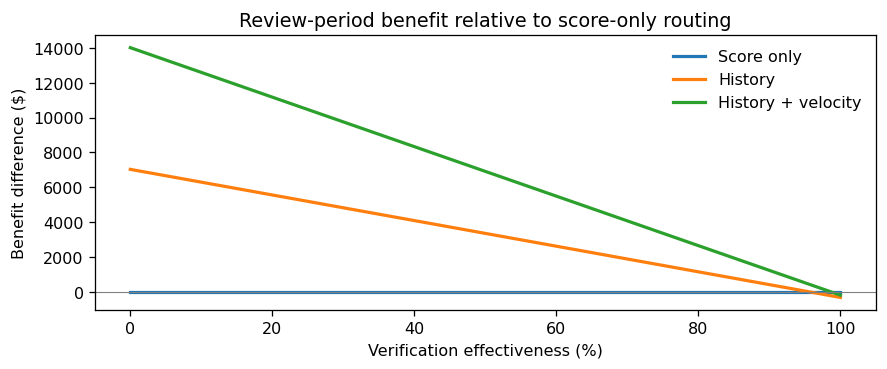

In [6]:
scenarios = pd.DataFrame(
    [
        ("Low friction", 0.60, 10.0, 0.50, 1.0),
        ("Base", 0.80, 35.0, 2.0, 3.0),
        ("High friction", 0.95, 100.0, 5.0, 7.0),
    ],
    columns=[
        "scenario",
        "verification_effectiveness",
        "legit_hard_cost",
        "legit_verify_cost",
        "ops_per_verify",
    ],
).set_index("scenario")


def policy_cost(row, config):
    return (
        row["legit_hard"] * config.legit_hard_cost
        + row["legit_verify"] * config.legit_verify_cost
        + row["verify"] * config.ops_per_verify
    )


def value(row, config, q=None):
    effectiveness = config.verification_effectiveness if q is None else q
    return row["fraud_hard_$"] + effectiveness * row["fraud_verify_$"] - policy_cost(row, config)


def crossing(a, b, config):
    intercept = value(a, config, 0) - value(b, config, 0)
    slope = a["fraud_verify_$"] - b["fraud_verify_$"]
    if np.isclose(slope, 0):
        return np.nan, ("Tie at every q" if np.isclose(intercept, 0) else "No crossing: parallel")
    q = -intercept / slope
    return q, ("Feasible" if 0 <= q <= 1 else "Outside 0–100%")


design_df = frame.iloc[design]
design_stats = pd.DataFrame(
    {p: totals(design_df, routes.loc[design_df.index, p]) for p in policies}
).T
base = scenarios.loc["Base"]
design_values = design_stats.apply(lambda row: value(row, base), axis=1)
chosen = design_values.idxmax()  # stable order favors the simpler policy if tied
review_values = pd.DataFrame(
    {
        name: comparison.apply(lambda row: value(row, cfg), axis=1)
        for name, cfg in scenarios.iterrows()
    }
)
display(
    scenarios,
    pd.concat([design_values.rename("Design, base"), review_values.add_prefix("Review, ")], axis=1),
)
breaks = []
for i, p in enumerate(policies):
    for other in policies[i + 1 :]:
        q, status = crossing(comparison.loc[p], comparison.loc[other], base)
        breaks.append(
            {
                "policy A": p,
                "policy B": other,
                "break_even_q": q,
                "interpretation": status,
                "A_minus_B_at_q0": value(comparison.loc[p], base, 0)
                - value(comparison.loc[other], base, 0),
                "A_minus_B_at_q1": value(comparison.loc[p], base, 1)
                - value(comparison.loc[other], base, 1),
            }
        )
display(pd.DataFrame(breaks))
# Diagnostic: price the same extreme-score, fewer-than-three-flags cohort under two actions.
cohort = review_df.loc[historical.loc[review_df.index, "reason"].eq("CC1.2")]
cohort_actions = {
    act: totals(cohort, pd.Series(act, index=cohort.index)) for act in ["Hard decline", "Verify"]
}
cohort_break, cohort_status = crossing(
    cohort_actions["Hard decline"], cohort_actions["Verify"], base
)
display(
    pd.DataFrame(
        [
            {
                "review_cohort": "Extreme score, <3 historical flags",
                "transactions": len(cohort),
                "fraud_dollars": cohort.loc[cohort.fraud.eq(1), "amount"].sum(),
                "legitimate": int(cohort.fraud.eq(0).sum()),
                "base_break_even_q": cohort_break,
                "interpretation": cohort_status,
            }
        ]
    )
)
print(
    f"Design-period base-case choice: {chosen}. Cohort comparison prices all purchases in this group identically; "
    "it is a sensitivity check outside the matched daily queue."
)
fig, ax = plt.subplots(figsize=(7.6, 3.1), layout="constrained")
grid = np.linspace(0, 1, 101)
for p in policies:
    delta = [
        value(comparison.loc[p], base, q) - value(comparison.loc[policies[0]], base, q)
        for q in grid
    ]
    ax.plot(100 * grid, delta, label=p, linewidth=2)
ax.axhline(0, color="0.5", linewidth=0.7)
ax.set(
    xlabel="Verification effectiveness (%)",
    ylabel="Benefit difference ($)",
    title="Review-period benefit relative to score-only routing",
)
ax.legend(frameon=False)
show_plot(fig)

## 6 · Monthly performance and workload
The table covers every transaction scored after fitting the model. Period and calendar month are shown together so changes of sample or partial months are visible. Metrics are transaction-weighted within each row. Queue peak is the largest daily number of verification requests in that interval. Fraud missed means the value of labeled fraud approved by the chosen policy. A drop in AP alone cannot distinguish prevalence changes from changes in ranking quality. A prospective monitor would calculate label-based metrics only after outcomes mature.

first_day    last_day   rows  fraud_rate     AP  score_p99  \
period month                                                                  
Design 2019-12  2019-12-28  2019-12-31  17178      0.0058 0.9414     0.8391   
       2020-01  2020-01-01  2020-01-31  52202      0.0066 0.9071     0.8703   
       2020-02  2020-02-01  2020-02-28  47791      0.0070 0.9387     0.8734   
       2020-03  2020-03-01  2020-03-31  72850      0.0061 0.9102     0.8406   
       2020-04  2020-04-01  2020-04-02   3259      0.0068 0.8744     0.8236   
Review 2020-04  2020-04-03  2020-04-30  63633      0.0044 0.8978     0.7514   
       2020-05  2020-05-01  2020-05-31  74343      0.0071 0.9237     0.8586   
       2020-06  2020-06-01  2020-06-21  57747      0.0058 0.8994     0.8181   

                alerts  legit_hard  verify  peak_verify_day  fraud_missed_$  \
period month                                                                  
Design 2019-12     120           1      88               22        124.7500   
       2020-01     643           0     570               22      5,898.7400   
       2020-02     572           0     496               22      3,040.7900   
       2020-03     741           5     612               22     10,501.0500   
       2020-04      35           0      35               18        857.5100   
Review 2020-04     575           1     530               22      2,570.5300   
       2020-05     809           8     654               22      7,381.6700   
       2020-06     526           6     423               22      7,505.3100   

                dollar_coverage  
period month                     
Design 2019-12           0.9979  
       2020-01           0.9677  
       2020-02           0.9835  
       2020-03           0.9551  
       2020-04           0.9375  
Review 2020-04           0.9814  
       2020-05           0.9743  
       2020-06           0.9584

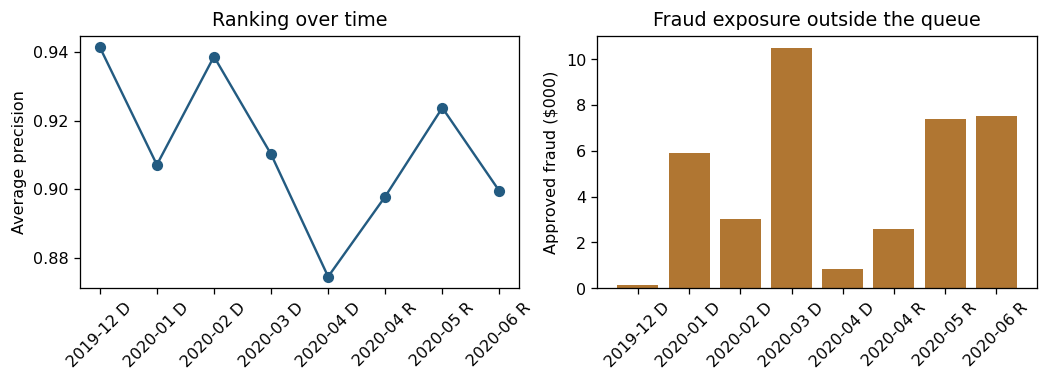

In [7]:
def monthly_report(rows, actions):
    out = []
    tmp = rows.assign(
        month=rows.day.dt.to_period("M").astype(str),
        period=np.where(rows.index < review_pos, "Design", "Review"),
    )
    for (period, month), g in tmp.groupby(["period", "month"], sort=False):
        a = actions.loc[g.index]
        t = totals(g, a)
        fraud_total = g.loc[g.fraud.eq(1), "amount"].sum()
        out.append(
            {
                "period": period,
                "month": month,
                "first_day": g.day.min().date(),
                "last_day": g.day.max().date(),
                "rows": len(g),
                "fraud_rate": g.fraud.mean(),
                "AP": average_precision_score(g.fraud, g.score) if g.fraud.sum() else np.nan,
                "score_p99": g.score.quantile(0.99),
                "alerts": t["alerts"],
                "legit_hard": t["legit_hard"],
                "verify": t["verify"],
                "peak_verify_day": int(a.eq("Verify").groupby(g.day).sum().max()),
                "fraud_missed_$": t["fraud_missed_$"],
                "dollar_coverage": 1 - t["fraud_missed_$"] / fraud_total if fraud_total else np.nan,
            }
        )
    return pd.DataFrame(out)


monthly = monthly_report(later, routes[chosen])
display(monthly.set_index(["period", "month"]))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), layout="constrained")
labels = monthly.month + " " + monthly.period.str[0]
axes[0].plot(labels, monthly.AP, "o-", color="#235b81")
axes[0].set(ylabel="Average precision", title="Ranking over time")
axes[1].bar(labels, monthly["fraud_missed_$"] / 1000, color="#b07632")
axes[1].set(ylabel="Approved fraud ($000)", title="Fraud exposure outside the queue")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
show_plot(fig)

## 7 · Model outage and behavioral fallback
If a score is missing, infinite or outside [0,1], five ordered behavioral rules can send a purchase to verification. Rules use only observed context: a recent burst with a spending spike, high daily spending at a new merchant, rapid spending in a risky category, a new merchant at a risky hour with a spike, or an unusual purchase following inactivity. Otherwise approve. Valid scores follow the ordinary first-hit rules. There are no automatic hard declines on the fallback path.

Run a deterministic outage drill: the simulated service is unavailable for one rotating clock hour per calendar day. Compare the fallback and ordinary policy **on exactly the affected transactions** and also evaluate an all-scores-unavailable stress case. This assesses unthrottled fallback demand. Queue overflow on a day indicates a staffing or triage problem under the assumed limit. The simulated schedule is independent of fraud labels.

In [8]:
FALLBACK_IDS = ("FB1", "FB2", "FB3", "FB4", "FB5")


def fallback_conditions(f, v):
    return pd.DataFrame(
        {
            "FB1": v.count_1h & f.spike,
            "FB2": v.spend_24h & f.new_merchant,
            "FB3": v.spend_1h & f.rapid & f.risky_category,
            "FB4": f.new_merchant & f.risky_hour & f.spike,
            "FB5": f.inactive & f.spike & v.count_24h,
        },
        index=f.index,
    )


def fallback_reasons(f, v):
    hit = fallback_conditions(f, v)
    return np.select([hit[k] for k in FALLBACK_IDS], FALLBACK_IDS, default="FB0")


def route_with_fallback(score, f, v):
    s = np.asarray(score, dtype=float)
    valid = np.isfinite(s) & (s >= 0) & (s <= 1)
    result = pd.DataFrame(index=f.index, columns=["action", "reason"], dtype=object)
    if valid.any():
        result.loc[valid, :] = first_hit(s[valid], f.loc[valid]).to_numpy()
    if (~valid).any():
        why = fallback_reasons(f.loc[~valid], v.loc[~valid])
        result.loc[~valid, "reason"] = why
        result.loc[~valid, "action"] = np.where(why == "FB0", "Approve", "Verify")
    return result


review_flags, review_velocity = flags.iloc[review], velocity_flags.iloc[review]
hour = raw.time.iloc[review].dt.hour.to_numpy()
outage = hour == ((review_df.day - review_df.day.min()).dt.days.to_numpy() * 7) % 24
damaged = review_df.score.to_numpy(copy=True)
damaged[outage] = np.nan
mixed = route_with_fallback(damaged, review_flags, review_velocity)
no_score = route_with_fallback(np.full(len(damaged), np.nan), review_flags, review_velocity)
normal = historical.loc[review_df.index]
assert (mixed.loc[~outage] == normal.loc[~outage]).all().all()
assert (mixed.loc[outage] == no_score.loc[outage]).all().all()


def outage_row(name, rows, action):
    t = totals(rows, action)
    queues = action.eq("Verify").groupby(rows.day).sum()
    return {
        "case": name,
        "rows": len(rows),
        "fraud_cases": int(rows.fraud.sum()),
        "alerts": t["alerts"],
        "verify": t["verify"],
        "recall": t["fraud_flagged"] / max(1, rows.fraud.sum()),
        "false_alerts": t["legit_verify"] + t["legit_hard"],
        "fraud_dollar_coverage": (t["fraud_hard_$"] + t["fraud_verify_$"])
        / max(0.01, rows.loc[rows.fraud.eq(1), "amount"].sum()),
        "peak_verify_day": queues.max(),
        "days_above_22": int(queues.gt(DAILY_VERIFICATIONS).sum()),
    }


outage_table = pd.DataFrame(
    [
        outage_row(
            "Ordinary rules / affected hour only",
            review_df.loc[outage],
            normal.loc[outage, "action"],
        ),
        outage_row(
            "Fallback / same affected hour", review_df.loc[outage], mixed.loc[outage, "action"]
        ),
        outage_row("Mixed service / whole period", review_df, mixed.action),
        outage_row("Full outage / whole period", review_df, no_score.action),
    ]
).set_index("case")
display(outage_table)
fallback_audit = (
    review_df.assign(reason=no_score.reason)
    .groupby("reason")
    .agg(rows=("fraud", "size"), fraud_cases=("fraud", "sum"))
)
display(fallback_audit.reindex(["FB1", "FB2", "FB3", "FB4", "FB5", "FB0"], fill_value=0))

,rows,fraud_cases,alerts,verify,recall,false_alerts,fraud_dollar_coverage,peak_verify_day,days_above_22
case,,,,,,,,,
Ordinary rules / affected hour only,8170,41,89,58,0.9512,50,0.9990,11,0
Fallback / same affected hour,8170,41,114,114,0.3171,101,0.4203,7,0
Mixed service / whole period,195723,1141,2170,1427,0.9202,1120,0.9514,41,19
Full outage / whole period,195723,1141,2974,2974,0.4014,2516,0.5052,98,58


,rows,fraud_cases
reason,,
FB1,503,141
FB2,706,217
FB3,1213,59
FB4,552,41
FB5,0,0
FB0,192749,683


## 8 · Executable regression tests for history and decisions
Each row names the condition being protected. The tests exercise the exact score cutoffs and adjacent floating-point values, overlapping first-hit rules, an extreme score with two versus three flags, ordinary and outage paths, and timestamp ties at both rolling-window boundaries. A synthetic returning customer has the same birth date in two formats. A second profile is new even when shopping at a familiar merchant. All checks call the same functions that generated the analysis.

In [9]:
checks = []


def check(label, actual, expected):
    np.testing.assert_equal(actual, expected, err_msg=label)
    checks.append(label)


def fixture_flags(*active):
    return pd.DataFrame([{k: k in active for k in flags.columns}])


def reason_case(label, score, active, expected):
    row = first_hit([score], fixture_flags(*active)).iloc[0]
    check(label, row.reason, expected)
    expected_action = {"CC1.1": "Hard decline", "CS1.1": "Approve", "CS1.2": "Approve"}.get(
        expected, "Verify"
    )
    check(label + " / action", row.action, expected_action)


below = lambda x: np.nextafter(float(x), -np.inf)
above = lambda x: np.nextafter(float(x), np.inf)
reason_case("Immediately below low", below(LOW), [], "CS1.1")
reason_case("At low", LOW, [], "CS1.2")
reason_case("Immediately above low", above(LOW), [], "CS1.2")
reason_case("Immediately below medium", below(MEDIUM), [], "CS1.2")
reason_case("At medium", MEDIUM, [], "CC1.6")
reason_case("Immediately above medium", above(MEDIUM), [], "CC1.6")
three = ["spike", "new_merchant", "risky_hour"]
reason_case("Immediately below hard", below(HARD), three, "CC1.4")
reason_case("At hard, three flags", HARD, three, "CC1.1")
reason_case("At hard, two flags", HARD, three[:2], "CC1.2")
reason_case("Above hard, three flags", above(HARD), three, "CC1.1")
reason_case(
    "Uncertain history wins when several rules match",
    MEDIUM,
    ["limited", "risky_hour", "new_merchant", "spike", "rapid"],
    "CC1.3",
)
reason_case("First purchase and risky category", MEDIUM, ["first", "risky_category"], "CC1.3")
reason_case("Uncertain history without risky context", MEDIUM, ["limited"], "CC1.6")
reason_case("Risky context without history uncertainty", MEDIUM, ["risky_hour"], "CC1.6")
reason_case(
    "Novel merchant and spike beat interval rule",
    MEDIUM,
    ["spike", "new_merchant", "rapid", "risky_hour"],
    "CC1.4",
)
reason_case("Novel merchant without spike", MEDIUM, ["new_merchant"], "CC1.6")
reason_case("Spike without novel merchant", MEDIUM, ["spike"], "CC1.6")
reason_case("Interval and category", MEDIUM, ["rapid", "risky_category"], "CC1.5")
reason_case("Inactivity and hour", MEDIUM, ["inactive", "risky_hour"], "CC1.5")
reason_case("Interval without risky context", MEDIUM, ["rapid"], "CC1.6")

toy = pd.DataFrame(
    {
        "time": pd.to_datetime(
            [
                "2020-01-01 00:00",
                "2020-01-01 23:00",
                "2020-01-02 00:00",
                "2020-01-02 00:00",
                "2020-01-02 00:00",
                "2020-01-02 00:01",
            ]
        ),
        "first": ["A", "A", "A", "A", "B", "A"],
        "last": "L",
        "street": "S",
        "merchant": "M",
        "dob": ["1980-07-23", "23/07/1980", "1980-07-23", "23/07/1980", "1980-07-23", "1980-07-23"],
        "amt": [10.0, 20.0, 40.0, 80.0, 100.0, 1.0],
    }
)
th = build_history(toy)
for col, expected in {
    "prior": [0, 1, 2, 2, 0, 4],
    "merchant_prior": [0, 1, 2, 2, 0, 4],
    "count_1h": [0, 0, 1, 1, 0, 2],
    "spend_1h": [0, 0, 20, 20, 0, 120],
    "count_24h": [0, 1, 2, 2, 0, 3],
    "spend_24h": [0, 10, 30, 30, 0, 140],
}.items():
    check(
        "Parsed profile, new customer, ties and exact rolling bounds / " + col,
        th[col].tolist(),
        expected,
    )
check(
    "Strictly earlier interval at equal timestamps", th.gap_minutes.iloc[2:4].tolist(), [60.0, 60.0]
)


def behavioral_boundary(prior, gap, ratio, merchant, category, hour):
    h = pd.DataFrame(
        [dict(prior=prior, gap_minutes=gap, amount_ratio=ratio, merchant_prior=merchant)]
    )
    return behavior_flags(h, [category], [hour]).iloc[0]


f = behavioral_boundary(99, 33.05, 2.055752432258314, 0, "shopping_net", 22)
check(
    "Included at rapid, spike, limited, new, category and hour boundaries",
    [
        bool(f[k])
        for k in ["rapid", "spike", "limited", "new_merchant", "risky_category", "risky_hour"]
    ],
    [True] * 6,
)
g = behavioral_boundary(100, above(33.05), below(2.055752432258314), 1, "other", 4)
check(
    "Just outside the same boundaries",
    [
        bool(g[k])
        for k in ["rapid", "spike", "limited", "new_merchant", "risky_category", "risky_hour"]
    ],
    [False] * 6,
)
check(
    "At inactivity cutoff", bool(behavioral_boundary(1, 1254.18, 1, 1, "other", 12).inactive), True
)
check(
    "Below inactivity cutoff",
    bool(behavioral_boundary(1, below(1254.18), 1, 1, "other", 12).inactive),
    False,
)
fallback_examples = [
    ("FB1", ["spike"], ["count_1h"]),
    ("FB2", ["new_merchant"], ["spend_24h"]),
    ("FB3", ["rapid", "risky_category"], ["spend_1h"]),
    ("FB4", ["new_merchant", "risky_hour", "spike"], []),
    ("FB5", ["inactive", "spike"], ["count_24h"]),
]


def fallback_case(score, active, velocity):
    return route_with_fallback(
        [score], fixture_flags(*active), pd.DataFrame([{k: k in velocity for k in velocity_cols}])
    ).iloc[0]


for expected, active, velocity in fallback_examples:
    result = fallback_case(np.nan, active, velocity)
    check("Fallback " + expected, (result.reason, result.action), (expected, "Verify"))
    for term in active + velocity:
        weakened = fallback_case(
            np.nan, [k for k in active if k != term], [k for k in velocity if k != term]
        )
        check(expected + " requires " + term, weakened.reason, "FB0")
for invalid in [np.nan, np.inf, -np.inf, -0.1, 1.1]:
    check(
        "Invalid score uses fallback " + str(invalid),
        fallback_case(invalid, three, ["count_1h", "spend_24h"]).reason,
        "FB1",
    )
check("Valid zero bypasses fallback", fallback_case(0.0, three, ["count_1h"]).reason, "CS1.1")
check("Valid one bypasses fallback", fallback_case(1.0, three, ["count_1h"]).reason, "CC1.1")
check("No-score default", fallback_case(np.nan, [], []).action, "Approve")
print(
    f"{len(checks)} named assertions passed. Daily capacity, identical alert sets and outage isolation also passed on real rows."
)

77 named assertions passed. Daily capacity, identical alert sets and outage isolation also passed on real rows.


## 9 · Daily gain and lift at staffing limits
For each review day, rank transactions by score and select the top 0.25%, 0.5% or 1%. Round the daily capacity down and break equal scores in chronological order. These are three separate staffing experiments. **Case gain** is the share of all fraud cases captured. **Dollar gain** is the share of fraud dollars captured. **Case lift** is case gain divided by the actual share of transactions reviewed, so 1× is the random-selection benchmark. The final table also reports the additional cases and dollars each capacity tier buys. This is a ranking analysis before hard-decline and verification decisions.

,reviews,actual_fraction,fraud_cases,fraud_dollars,precision,case_gain,dollar_gain,case_lift,additional_cases,additional_fraud_$
budget_pct,,,,,,,,,,
0.2500,445,0.0023,396,"257,244.5800",0.8899,0.3471,0.4246,152.6481,396,"257,244.5800"
0.5000,943,0.0048,694,"437,121.9600",0.7359,0.6082,0.7214,126.2420,298,"179,877.3800"
1.0000,1919,0.0098,996,"572,142.9200",0.5190,0.8729,0.9443,89.0309,302,"135,020.9600"


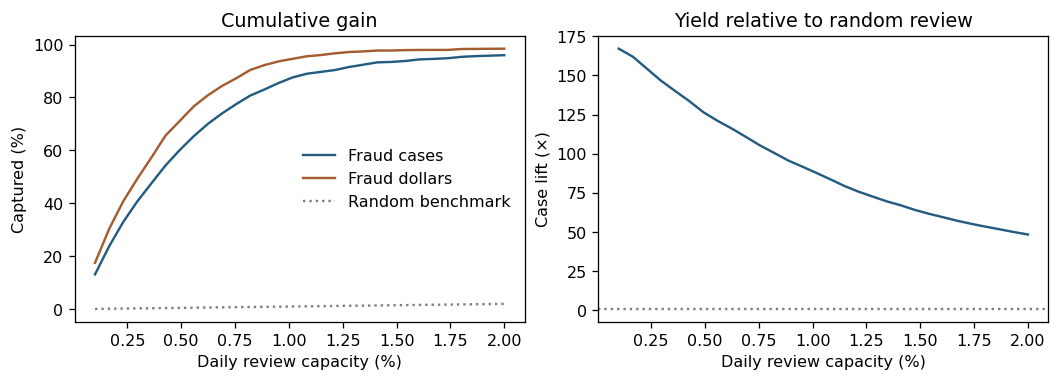

In [10]:
ranked = review_df.sort_values("score", ascending=False, kind="stable").copy()
ranked["rank_in_day"] = ranked.groupby("day", sort=False).cumcount() + 1
ranked["daily_n"] = ranked.groupby("day", sort=False).score.transform("size")
all_fraud = int(ranked.fraud.sum())
all_fraud_dollars = ranked.loc[ranked.fraud.eq(1), "amount"].sum()


def capacity_row(fraction):
    selected = ranked.loc[ranked.rank_in_day.le(np.floor(fraction * ranked.daily_n))]
    fraud_selected = selected.loc[selected.fraud.eq(1)]
    rate = len(selected) / len(ranked)
    gain = len(fraud_selected) / all_fraud
    return {
        "budget_pct": 100 * fraction,
        "reviews": len(selected),
        "actual_fraction": rate,
        "fraud_cases": len(fraud_selected),
        "fraud_dollars": fraud_selected.amount.sum(),
        "precision": len(fraud_selected) / max(len(selected), 1),
        "case_gain": gain,
        "dollar_gain": fraud_selected.amount.sum() / all_fraud_dollars,
        "case_lift": gain / rate if rate else np.nan,
    }


capacity = pd.DataFrame([capacity_row(f) for f in (0.0025, 0.005, 0.01)]).set_index("budget_pct")
capacity["additional_cases"] = capacity.fraud_cases.diff().fillna(capacity.fraud_cases).astype(int)
capacity["additional_fraud_$"] = capacity.fraud_dollars.diff().fillna(capacity.fraud_dollars)
display(capacity)
assert (
    capacity.fraud_cases.is_monotonic_increasing and capacity.fraud_dollars.is_monotonic_increasing
)
points = pd.DataFrame([capacity_row(f) for f in np.linspace(0.001, 0.02, 30)])
fig, axes = plt.subplots(1, 2, figsize=(9.1, 3.2), layout="constrained")
axes[0].plot(points.budget_pct, 100 * points.case_gain, label="Fraud cases", color="#235b81")
axes[0].plot(points.budget_pct, 100 * points.dollar_gain, label="Fraud dollars", color="#a45b30")
axes[0].plot(points.budget_pct, points.budget_pct, ":", color="0.5", label="Random benchmark")
axes[0].set(xlabel="Daily review capacity (%)", ylabel="Captured (%)", title="Cumulative gain")
axes[0].legend(frameon=False)
axes[1].plot(points.budget_pct, points.case_lift, color="#235b81")
axes[1].axhline(1, linestyle=":", color="0.5")
axes[1].set(
    xlabel="Daily review capacity (%)",
    ylabel="Case lift (×)",
    title="Yield relative to random review",
)
show_plot(fig)

## 10 · Interpretation and audit trail
The research decision is whether the rolling indicators improve the allocation of a fixed daily workload. The table below isolates the **incremental effect of velocity versus history alone** and gives the model interpretation for this run. The strongest permutation effect identifies a predictive dependency. It does not establish causation or imply that the same variable should trigger an automatic decline.

**Course references.** Lecture 4, pp. 34–39 covers aggregation windows and PCA. Lectures 5/8, pp. 24–25, 40 and 11/12, pp. 35–38, 52, 54 cover feature contribution and capacity diagnostics. Lectures 13/14, pp. 23, 30–40 and 15/18, pp. 16–35, 37 cover rule economics, fallback, boundary testing, monitoring and stakeholder communication. The experimental design, assumptions, code and measured results here are specific to this project.

In [11]:
velocity_change = comparison.loc["History + velocity"] - comparison.loc["History"]
changed = int((review_routes["History + velocity"] != review_routes["History"]).sum())
display(
    velocity_change[["legit_hard", "fraud_hard_$", "fraud_verify_$", "alerts", "verify"]].to_frame(
        "Velocity minus history"
    )
)
print(
    f"{changed:,} purchases changed action. Base-case benefit change: "
    f'${review_values.loc["History + velocity","Base"]-review_values.loc["History","Base"]:,.2f}.'
)
meaning = {
    "amt_log1p": "the size of the purchase",
    "category": "the type of merchant activity",
    "merchant_distance_km": "the distance between customer and merchant",
    "trans_hour": "the hour of purchase",
    "hour_sin": "the cyclic hour of purchase",
    "hour_cos": "the cyclic hour of purchase",
    "city_pop_log1p": "the customer city population",
    "age_at_transaction": "customer age at purchase",
    "trans_day_of_week": "the purchase weekday",
    "trans_month": "the purchase month",
    "is_weekend": "weekend activity",
    "is_night": "overnight purchasing",
    "day_sin": "the cyclic purchase weekday",
    "day_cos": "the cyclic purchase weekday",
    "lat": "customer latitude",
    "long": "customer longitude",
    "state": "customer state",
    "gender": "the recorded gender category",
}
for row in importance.head(3).itertuples():
    print(
        f"{row.feature} ({meaning[row.feature]}): mean permutation AP decrease {row.mean_AP_drop:.4f}."
    )
print(
    f"Removing {ablation.index[0].lower()} had the largest group effect: AP drop {ablation.iloc[0].AP_drop_vs_full:.4f}."
)
print(
    "Feature groups with AP improvement on removal:",
    ", ".join(ablation.index[ablation.AP_drop_vs_full < 0]) or "none",
)
print(
    "Small or negative changes are candidates for confirmation across future time windows; one review interval cannot establish durable redundancy."
)

# Recompute modeled benefit transaction by transaction to check the aggregate calculation.
for policy in policies:
    action = review_routes[policy]
    hard = action.eq("Hard decline")
    verify = action.eq("Verify")
    fraud = review_df.fraud.eq(1)
    for scenario, config in scenarios.iterrows():
        credits = (
            review_df.amount
            * fraud
            * (hard.astype(float) + config.verification_effectiveness * verify)
        )
        costs = (
            (~fraud) * hard * config.legit_hard_cost
            + (~fraud) * verify * config.legit_verify_cost
            + verify * config.ops_per_verify
        )
        np.testing.assert_allclose(
            (credits - costs).sum(), review_values.loc[policy, scenario], atol=1e-7
        )
for row in breaks:
    if row["interpretation"] == "Feasible":
        q = row["break_even_q"]
        np.testing.assert_allclose(
            value(comparison.loc[row["policy A"]], base, q),
            value(comparison.loc[row["policy B"]], base, q),
            atol=1e-7,
        )
print(
    "All nine policy/scenario values reconcile against individual transactions, and every feasible crossing balances."
)

144 purchases changed action. Base-case benefit change: $1,502.95.
amt_log1p (the size of the purchase): mean permutation AP decrease 0.9130.
category (the type of merchant activity): mean permutation AP decrease 0.6624.
age_at_transaction (customer age at purchase): mean permutation AP decrease 0.1548.
Removing amount had the largest group effect: AP drop 0.5874.
Feature groups with AP improvement on removal: none
Small or negative changes are candidates for confirmation across future time windows; one review interval cannot establish durable redundancy.
All nine policy/scenario values reconcile against individual transactions, and every feasible crossing balances.


,Velocity minus history
legit_hard,-4.0000
fraud_hard_$,"6,854.7300"
fraud_verify_$,"-6,854.7300"
alerts,0.0000
verify,0.0000


## 11 · Can the policy work in authorization order?

**Experiment 1.** Replay purchases in timestamp order. At each arrival the decision sees the current score, strictly prior history, velocity indicators and the slots already used that day. Decisions are final. An approval made at 9 a.m. cannot be replaced by an evening purchase. Rows with equal timestamps use their original file order. Time and calendar-day boundaries follow the simulator.

**Frozen operating rules.** Keep the original daily limits of 30 interventions and 22 verifications. Reserve the remaining eight slots for extreme-score hard declines. Hard-decline an extreme-score purchase only when it meets the policy's priority threshold and a hard slot remains. Otherwise send a score-qualified purchase to verification if a slot is free. Approve a purchase that cannot be served and record the capacity denial. The two policies have identical daily limits. Actual counts can differ because they see different qualifying transactions at different times.

**Fair design calibration.** Score-only prioritizes by risk score. History + velocity prioritizes by the number of historical and rolling flags, breaking ties by risk score. On the earlier design period, set each priority threshold to target the original batch policy's number of hard declines. For each day the eight highest extreme-band priorities determine how many applicants could meet any threshold under that cap. Their values are used only to set the design-period threshold. The review replay never ranks future purchases. The design's first partial day and the review's final partial day are included, as in the batch benchmark.

In [12]:
from itertools import combinations
from IPython.display import HTML
from html import escape

STREAM_POLICIES = ("Score only", "History + velocity")
HARD_SLOTS = DAILY_ALERTS - DAILY_VERIFICATIONS


def signal_frame(rows):
    return pd.DataFrame(
        {
            "time": raw.loc[rows.index, "time"],
            "score": rows.score,
            "flags": rows.history + rows.velocity,
        },
        index=rows.index,
    )


def priority_signals(signals, policy):
    if policy == "Score only":
        return signals.score.to_numpy()
    if policy == "History + velocity":
        # A score in [0,1] cannot outweigh a difference of one flag.
        return 2.0 * signals["flags"].to_numpy() + signals.score.to_numpy()
    raise ValueError(f"Unknown routing policy: {policy}")


def fit_gate(signals, policy, hard_target):
    if hard_target == 0:
        return np.inf
    extreme = signals.score.ge(HARD)
    candidates = pd.DataFrame(
        {
            "priority": priority_signals(signals, policy)[extreme],
            "day": signals.loc[extreme, "time"].dt.normalize(),
        }
    )
    top_per_day = candidates.groupby("day").priority.nlargest(HARD_SLOTS).to_numpy()
    if not 0 < hard_target <= len(top_per_day):
        raise ValueError("Design-period hard-decline target is infeasible")
    return np.sort(top_per_day)[-hard_target]


def stream_replay(signals, policy, gate, outage_mask=None, fallback_hit=None):
    if not signals.time.is_monotonic_increasing or not signals.index.is_unique:
        raise ValueError("Expected chronological transactions with unique row indices")
    n = len(signals)
    score = signals.score.to_numpy()
    available = np.isfinite(score) & (score >= 0) & (score <= 1)
    if outage_mask is not None:
        unavailable = np.asarray(outage_mask, dtype=bool)
        if unavailable.shape != (n,):
            raise ValueError("Misaligned outage mask")
        available &= ~unavailable
    hit = np.zeros(n, dtype=bool) if fallback_hit is None else np.asarray(fallback_hit, dtype=bool)
    if hit.shape != (n,):
        raise ValueError("Misaligned fallback inputs")
    hard_candidate = available & (score >= HARD) & (priority_signals(signals, policy) >= gate)
    candidate = (available & (score >= MEDIUM)) | (~available & hit)
    actions = np.full(n, "Approve", dtype=object)
    blocked = np.zeros(n, dtype=bool)
    dates = signals.time.to_numpy().astype("datetime64[D]").astype("int64")
    current_day = None
    for i in np.flatnonzero(candidate):
        if dates[i] != current_day:
            current_day, used_hard, used_verify = dates[i], 0, 0
        if hard_candidate[i] and used_hard < HARD_SLOTS:
            actions[i] = "Hard decline"
            used_hard += 1
        elif used_verify < DAILY_VERIFICATIONS:
            actions[i] = "Verify"
            used_verify += 1
        else:
            blocked[i] = True
    return pd.DataFrame({"action": actions, "blocked": blocked}, index=signals.index)


design_signals = signal_frame(design_df)
review_signals = signal_frame(review_df)
target_hard = int(design_stats.loc["Score only", "hard"])
gates = {p: fit_gate(design_signals, p, target_hard) for p in STREAM_POLICIES}
online_routes = {p: stream_replay(review_signals, p, gates[p]) for p in STREAM_POLICIES}
design_gate_check = pd.DataFrame(
    [
        {
            "policy": p,
            "priority_threshold": gates[p],
            "design_target": target_hard,
            "achieved_hard_declines": stream_replay(design_signals, p, gates[p])
            .action.eq("Hard decline")
            .sum(),
        }
        for p in STREAM_POLICIES
    ]
).set_index("policy")
display(design_gate_check)
print("A tied priority at the design threshold can cause a small difference from the target.")

A tied priority at the design threshold can cause a small difference from the target.


,priority_threshold,design_target,achieved_hard_declines
policy,,,
Score only,0.9974,310,311
History + velocity,10.9977,310,310


### Queue fill times and the business comparison

Record the timestamp of the 22nd verification and the eighth hard decline each day. An empty time means that queue never filled. For purchases approved because verification was full and no eligible hard slot was available, count the missed fraud cases and dollars. The expandable table contains every review day. Times are simulator local-clock values as recorded in the input. Aggregate benefit uses the same base-case costs and 80% verification effectiveness as the batch comparison.

In [13]:
def days_table(title, frame):
    # Keep all dated rows available in the notebook without exposing transaction-level data.
    content = frame.to_html(max_rows=None, float_format=lambda v: f"{v:,.2f}", na_rep="—")
    display(
        HTML(f"<details><summary>{escape(title)} ({len(frame)} rows)</summary>{content}</details>")
    )


def queue_days(rows, replay):
    action = replay.action
    calendar = rows.day.drop_duplicates().to_numpy()

    def filled_time(action_name, limit):
        subset = rows.loc[action.eq(action_name), "day"]
        last = subset[subset.groupby(subset).cumcount().eq(limit - 1)]
        return pd.Series(
            raw.loc[last.index, "time"].to_numpy(), index=last.to_numpy(), dtype="datetime64[ns]"
        ).reindex(calendar)

    info = pd.DataFrame(index=pd.DatetimeIndex(calendar, name="day"))
    for action_name, label, limit in [
        ("Verify", "verify", DAILY_VERIFICATIONS),
        ("Hard decline", "hard", HARD_SLOTS),
    ]:
        info[label] = action.eq(action_name).groupby(rows.day).sum()
        info[label + "_filled"] = filled_time(action_name, limit)
    info["blocked"] = replay.blocked.groupby(rows.day).sum()
    missed = replay.blocked & rows.fraud.eq(1)
    info["blocked_frauds"] = missed.groupby(rows.day).sum()
    info["blocked_fraud_$"] = rows.amount.where(missed, 0).groupby(rows.day).sum()
    return info


queue_log = {p: queue_days(review_df, online_routes[p]) for p in STREAM_POLICIES}


def clock_minute(timestamps):
    filled = timestamps.dropna()
    if filled.empty:
        return "—"
    minutes = int(np.median(filled.dt.hour * 60 + filled.dt.minute))
    return f"{minutes//60:02d}:{minutes%60:02d}"


queue_totals = pd.DataFrame(
    [
        {
            "policy": p,
            "days": len(q),
            "days_verify_full": q.verify_filled.notna().sum(),
            "median_verify_fill": clock_minute(q.verify_filled),
            "days_hard_full": q.hard_filled.notna().sum(),
            "median_hard_fill": clock_minute(q.hard_filled),
            "capacity_approvals": q.blocked.sum(),
            "capacity_approved_frauds": q.blocked_frauds.sum(),
            "capacity_approved_fraud_$": q["blocked_fraud_$"].sum(),
        }
        for p, q in queue_log.items()
    ]
).set_index("policy")
display(queue_totals)
daily_queues = (
    pd.concat(queue_log, names=["policy", "day"]).reorder_levels(["day", "policy"]).sort_index()
)
for col in ["verify_filled", "hard_filled"]:
    daily_queues[col] = daily_queues[col].dt.strftime("%H:%M:%S").fillna("—")
days_table("Daily queue utilization, first fill times and capacity approvals", daily_queues)
online_stats = pd.DataFrame(
    {p: totals(review_df, online_routes[p].action) for p in STREAM_POLICIES}
).T
online_values = online_stats.apply(lambda row: value(row, base), axis=1)
summary_rows = []
for mode, stats, benefits in [
    ("Batch", comparison, review_values["Base"]),
    ("Streaming", online_stats, online_values),
]:
    for p in STREAM_POLICIES:
        s = stats.loc[p]
        summary_rows.append(
            {
                "mode": mode,
                "policy": p,
                "hard": int(s.hard),
                "verify": int(s.verify),
                "fraud_flagged": int(s.fraud_flagged),
                "legit_hard": int(s.legit_hard),
                "approved_fraud_$": s["fraud_missed_$"],
                "base_benefit_$": benefits.loc[p],
            }
        )
display(pd.DataFrame(summary_rows).set_index(["mode", "policy"]).round(2))
batch_gap = (
    review_values.loc["History + velocity", "Base"] - review_values.loc["Score only", "Base"]
)
stream_gap = online_values["History + velocity"] - online_values["Score only"]
retained = stream_gap / batch_gap if batch_gap else np.nan
print(
    f"Batch difference: {batch_gap:+,.2f} USD. Streaming difference: {stream_gap:+,.2f} USD. "
    f"Streaming / batch difference: {retained:.1%}. "
    "This ratio compares two policy differences; values above 100% or below zero are possible."
)

Batch difference: +2,643.69 USD. Streaming difference: +10,919.47 USD. Streaming / batch difference: 413.0%. This ratio compares two policy differences; values above 100% or below zero are possible.


,days,days_verify_full,median_verify_fill,days_hard_full,median_hard_fill,capacity_approvals,capacity_approved_frauds,capacity_approved_fraud_$
policy,,,,,,,,
Score only,80,38,23:13,14,23:30,328,124,"64,026.5900"
History + velocity,80,39,23:07,5,23:28,346,110,"52,878.1400"


hard  verify  fraud_flagged  legit_hard  \
mode      policy                                                        
Batch     Score only           303    1607           1042           9   
          History + velocity   303    1607           1042          15   
Streaming Score only           320    1497            952           1   
          History + velocity   273    1526            966           3   

                              approved_fraud_$  base_benefit_$  
mode      policy                                                
Batch     Score only               17,457.5100    502,709.1400  
          History + velocity       17,457.5100    505,352.8400  
Streaming Score only               78,670.7000    455,464.0500  
          History + velocity       67,522.2500    466,383.5300

## 12 · Is the economic difference stable across days?

**Experiment 2.** Calculate incremental base-case benefit for every transaction, subtract score-only from history + velocity within the same purchase, and sum within calendar day. Repeat for batch and streaming. The cumulative plot shows when each difference arises. Count gains, losses and ties to the nearest cent. Also report what remains after subtracting the three most favorable days or the three largest favorable individual fraud contributions. These are concentration diagnostics with the observed decisions held fixed.

For a 95% percentile interval for the **80-day total difference**, resample paired sequences of seven consecutive days with replacement, concatenate blocks and truncate to 80 days. Use 10,000 seeded circular moving-block replicates so each day can start a block. A block can wrap from the end to the beginning. Both policies and both modes use exactly the same sampled dates. This preserves short runs of dependent daily outcomes while treating weeks as representative of future weeks. The period contains only about 11 weeks, and its final day is partial. The interval is conditional on the trained model, policy thresholds, cost assumptions and this historical period.

,Batch,Streaming,Batch cumulative,Streaming cumulative
day,,,,
2020-04-03,0.00,-30.43,0.00,-30.43
2020-04-04,0.00,0.00,0.00,-30.43
2020-04-05,0.00,0.00,0.00,-30.43
2020-04-06,0.00,-136.38,0.00,-166.81
2020-04-07,391.70,-159.10,391.70,-325.91
2020-04-08,0.00,236.08,391.70,-89.83
2020-04-09,0.00,213.74,391.70,123.92
2020-04-10,0.00,375.97,391.70,499.88
2020-04-11,0.00,0.00,391.70,499.88


,observed_$,lower_95,upper_95,gain_days,loss_days,tie_days,best_day_$,worst_day_$,excluding_best_3_days_$,excluding_top_3_frauds_$
mode,,,,,,,,,,
Batch,"2,643.6900",-53.3800,"5,193.5800",30,14,36,391.7000,-430.6300,"1,574.0400","1,895.2600"
Streaming,"10,919.4700","1,434.9300","20,750.9600",38,33,9,"1,715.3000","-1,379.0300","5,891.3800","7,599.0400"


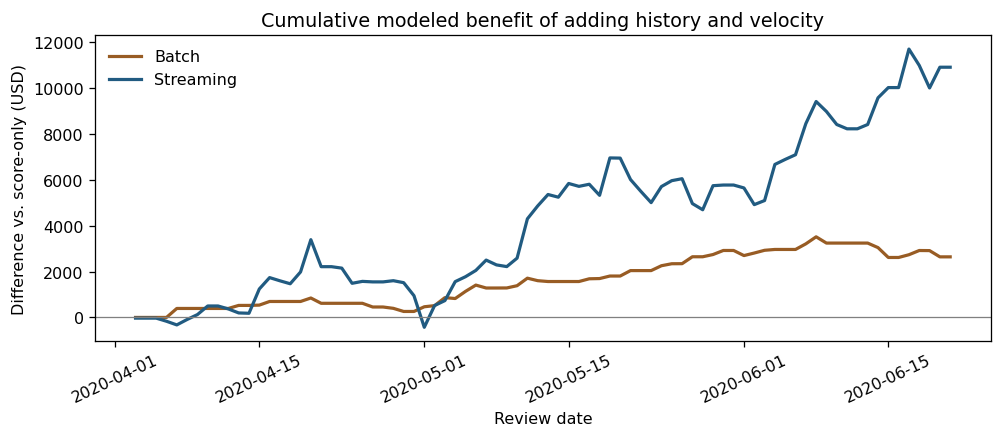

,purchases,frauds,net_difference_USD
group,,,
Different action on common alert,273,271,"-1,085.2800"
Newly flagged,51,44,"30,563.2800"
No longer flagged,69,30,"-18,558.5200"
Same decision,195330,796,0.0000


In [14]:
def transaction_value(rows, action):
    hard = action.eq("Hard decline")
    verify = action.eq("Verify")
    fraud = rows.fraud.eq(1)
    saved = rows.amount.where(fraud, 0) * (
        hard.astype(float) + base.verification_effectiveness * verify
    )
    costs = (
        (hard & ~fraud) * base.legit_hard_cost
        + (verify & ~fraud) * base.legit_verify_cost
        + verify * base.ops_per_verify
    )
    return saved - costs


outcomes = {}
for mode, actions in {
    "Batch": {p: review_routes[p] for p in STREAM_POLICIES},
    "Streaming": {p: online_routes[p].action for p in STREAM_POLICIES},
}.items():
    for p in STREAM_POLICIES:
        outcomes[mode, p] = transaction_value(review_df, actions[p])
by_txn = pd.DataFrame(outcomes)
by_day = by_txn.groupby(review_df.day).sum()
calendar = pd.date_range(review_df.day.min(), review_df.day.max(), freq="D", name="day")
by_day = by_day.reindex(calendar, fill_value=0)
txn_delta = pd.DataFrame(
    {k: by_txn[k, "History + velocity"] - by_txn[k, "Score only"] for k in ("Batch", "Streaming")}
)
daily_delta = txn_delta.groupby(review_df.day).sum().reindex(calendar, fill_value=0)
np.testing.assert_allclose(daily_delta.sum(), [batch_gap, stream_gap], atol=1e-6)
days_table(
    "Daily benefit difference (USD) and running total",
    daily_delta.join(daily_delta.cumsum().add_suffix(" cumulative")),
)

N_BOOT, BLOCK, BOOT_SEED = 10_000, 7, 731
rng = np.random.default_rng(BOOT_SEED)
n_days = len(calendar)
starts = rng.integers(0, n_days, size=(N_BOOT, int(np.ceil(n_days / BLOCK))))
sampled_days = ((starts[:, :, None] + np.arange(BLOCK)) % n_days).reshape(N_BOOT, -1)[:, :n_days]
boot = daily_delta.to_numpy()[sampled_days].sum(axis=1)
interval = pd.DataFrame(
    np.quantile(boot, [0.025, 0.975], axis=0).T,
    index=daily_delta.columns,
    columns=["lower_95", "upper_95"],
)
stability = []
for mode in daily_delta:
    daily = daily_delta[mode]
    sign = daily.round(2)
    positive_frauds = txn_delta.loc[review_df.fraud.eq(1) & txn_delta[mode].gt(0), mode]
    stability.append(
        {
            "mode": mode,
            "observed_$": daily.sum(),
            "lower_95": interval.at[mode, "lower_95"],
            "upper_95": interval.at[mode, "upper_95"],
            "gain_days": int(sign.gt(0).sum()),
            "loss_days": int(sign.lt(0).sum()),
            "tie_days": int(sign.eq(0).sum()),
            "best_day_$": daily.max(),
            "worst_day_$": daily.min(),
            "excluding_best_3_days_$": daily.sum() - daily.clip(lower=0).nlargest(3).sum(),
            "excluding_top_3_frauds_$": daily.sum() - positive_frauds.nlargest(3).sum(),
        }
    )
stability = pd.DataFrame(stability).set_index("mode")
display(stability.round(2))
fig, ax = plt.subplots(figsize=(8.6, 3.7), layout="constrained")
for mode, color in [("Batch", "#985c24"), ("Streaming", "#215b81")]:
    ax.plot(calendar, daily_delta[mode].cumsum(), label=mode, color=color, linewidth=2)
ax.axhline(0, color="0.5", linewidth=0.8)
ax.set(
    title="Cumulative modeled benefit of adding history and velocity",
    xlabel="Review date",
    ylabel="Difference vs. score-only (USD)",
)
ax.legend(frameon=False)
ax.tick_params(axis="x", labelrotation=25)
show_plot(fig)

# Separate changes in who was flagged from changes in how a shared alert was routed.
a_score = online_routes["Score only"].action
a_history = online_routes["History + velocity"].action
switch_groups = np.select(
    [
        a_score.eq("Approve") & a_history.ne("Approve"),
        a_score.ne("Approve") & a_history.eq("Approve"),
        a_score.ne("Approve") & a_history.ne("Approve") & a_score.ne(a_history),
    ],
    ["Newly flagged", "No longer flagged", "Different action on common alert"],
    default="Same decision",
)
decomposition = (
    pd.DataFrame(
        {"group": switch_groups, "fraud": review_df.fraud, "delta_$": txn_delta["Streaming"]},
        index=review_df.index,
    )
    .groupby("group")
    .agg(
        purchases=("delta_$", "size"),
        frauds=("fraud", "sum"),
        net_difference_USD=("delta_$", "sum"),
    )
)
display(decomposition.round(2))
np.testing.assert_allclose(decomposition.net_difference_USD.sum(), stream_gap, atol=1e-6)

## 13 · Which fallback rules earn a scarce verification slot?

**Experiment 3.** Evaluate outage behavior at the same 22-verification daily limit. In a full outage the fallback can never hard-decline. Serve eligible fallback purchases in arrival order. Once all verifications are used, approve later fallback candidates and count them as blocked. During a rotating-hour outage, normal approvals, hard declines and fallback verifications share the same live day counters. There is no separate quota for the missing-score hour.

Use the five existing behavioral predicates. **FB1:** unusually many purchases in the last hour and a current amount spike. **FB2:** unusually high prior 24-hour spending and a new merchant. **FB3:** high prior-hour spending, a rapid repeat and a risky category. **FB4:** new merchant, risky hour and a current amount spike. **FB5:** long inactivity, a current amount spike and an unusually high 24-hour purchase count. All boundaries are inherited from the fitting period.

Choose the simpler policy on the earlier design period. Replay every single rule and every two-rule combination under a full outage, then maximize the existing base-case benefit. Ties favor fewer rules and then the original rule order. This optimizes for a full outage; short rotating outages are evaluated separately. Freeze the chosen subset before scoring the review outcomes.

In [15]:
design_hits = fallback_conditions(flags.iloc[design], velocity_flags.iloc[design])
review_hits = fallback_conditions(review_flags, review_velocity)
outage_policy = "History + velocity"


def union_hits(hits, active):
    if not active:
        return np.zeros(len(hits), dtype=bool)
    return hits.loc[:, list(active)].any(axis=1).to_numpy()


def replay_outage(signals, hits, active, mask):
    return stream_replay(
        signals,
        outage_policy,
        gates[outage_policy],
        outage_mask=mask,
        fallback_hit=union_hits(hits, active),
    )


full_design = np.ones(len(design_signals), dtype=bool)
full_review = np.ones(len(review_signals), dtype=bool)
candidate_rows = []
for size in (1, 2):
    for active in combinations(FALLBACK_IDS, size):
        result = replay_outage(design_signals, design_hits, active, full_design)
        metrics = totals(design_df, result.action)
        candidate_rows.append(
            {
                "rules": active,
                "size": size,
                "design_value_$": value(metrics, base),
                "fraud_cases": metrics["fraud_flagged"],
                "false_alerts": metrics["legit_verify"],
                "verify": metrics["verify"],
            }
        )
fallback_selection = pd.DataFrame(candidate_rows).sort_values(
    ["design_value_$", "size", "rules"], ascending=[False, True, True], kind="stable"
)
simple_rules = fallback_selection.iloc[0].rules
display(fallback_selection.set_index("rules").round(2))
print("Frozen simpler fallback:", " + ".join(simple_rules))

# Incremental performance: removing a rule can free slots for later rules.
full_five = replay_outage(review_signals, review_hits, FALLBACK_IDS, full_review)
first_credit = pd.Series(fallback_reasons(review_flags, review_velocity), index=review_df.index)
old_totals = totals(review_df, full_five.action)
rule_rows = []
for rule in FALLBACK_IDS:
    others = tuple(k for k in FALLBACK_IDS if k != rule)
    without = replay_outage(review_signals, review_hits, others, full_review)
    without_stats = totals(review_df, without.action)
    observed = full_five.action.eq("Verify") & first_credit.eq(rule)
    rule_rows.append(
        {
            "rule": rule,
            "any_match": int(review_hits[rule].sum()),
            "first_hit_served_frauds": int((observed & review_df.fraud.eq(1)).sum()),
            "first_hit_served_false": int((observed & review_df.fraud.eq(0)).sum()),
            "incremental_fraud_cases": old_totals["fraud_flagged"] - without_stats["fraud_flagged"],
            "incremental_false_alerts": old_totals["legit_verify"] - without_stats["legit_verify"],
            "incremental_verified_fraud_$": old_totals["fraud_verify_$"]
            - without_stats["fraud_verify_$"],
        }
    )
contribution = pd.DataFrame(rule_rows).set_index("rule")
display(contribution.round(2))
assert contribution.first_hit_served_frauds.sum() == old_totals["fraud_flagged"]
assert contribution.first_hit_served_false.sum() == old_totals["legit_verify"]
print(
    "Incremental = capped five-rule result minus capped result with that rule removed. "
    "A negative value means reassigning its slots improved that measure. Overlap and displacement make these effects non-additive."
)

Frozen simpler fallback: FB1 + FB4
Incremental = capped five-rule result minus capped result with that rule removed. A negative value means reassigning its slots improved that measure. Overlap and displacement make these effects non-additive.


,size,design_value_$,fraud_cases,false_alerts,verify
rules,,,,,
"(FB1, FB4)",2,"177,538.7800",319,893,1212
"(FB1, FB2)",2,"170,267.6600",339,644,983
"(FB2, FB3)",2,"152,934.6500",314,1081,1395
"(FB3, FB4)",2,"149,668.9400",286,1325,1611
"(FB2, FB4)",2,"132,557.2600",295,1021,1316
"(FB4,)",1,"130,338.9200",242,669,911
"(FB4, FB5)",2,"130,338.9200",242,669,911
"(FB1, FB3)",2,"123,823.5500",218,995,1213
"(FB2,)",1,"117,296.1900",252,448,700


,any_match,first_hit_served_frauds,first_hit_served_false,incremental_fraud_cases,incremental_false_alerts,incremental_verified_fraud_$
rule,,,,,,
FB1,503,52,114,-2,33,"-1,486.7700"
FB2,739,113,235,25,88,"-5,223.9500"
FB3,1411,30,709,-58,340,"-40,457.3500"
FB4,690,26,372,-20,184,"-11,955.3400"
FB5,0,0,0,0,0,0.0000


### Full-day and shared-queue outage results

Compare the original unthrottled fallback, all five rules under the cap, and the simpler frozen fallback under the same cap. For the rotating-hour drill, also compare ordinary streaming service on those exact transactions and report whole-day results: a fallback verification early in the day can displace a healthy-service verification later. The **affected-only** rows measure the outage cohort; the **peak whole-day verifications** column still counts every customer sharing that day's queue. Capacity-blocked counts apply to the row's evaluation cohort. Coverage is observed fraud exposure routed to verification or decline, before customer response and recovery.

In [16]:
simple_full = replay_outage(review_signals, review_hits, simple_rules, full_review)
rotating_five = replay_outage(review_signals, review_hits, FALLBACK_IDS, outage)
rotating_simple = replay_outage(review_signals, review_hits, simple_rules, outage)
ordinary_online = online_routes[outage_policy]


def service_report(name, result, cohort_mask):
    a = result.loc[cohort_mask, "action"]
    subset = review_df.loc[cohort_mask]
    t = totals(subset, a)
    fraud_dollars = subset.loc[subset.fraud.eq(1), "amount"].sum()
    queue = result.action.eq("Verify").groupby(review_df.day).sum()
    return {
        "case": name,
        "rows": len(subset),
        "verify": t["verify"],
        "hard": t["hard"],
        "frauds_flagged": t["fraud_flagged"],
        "false_alerts": t["legit_verify"] + t["legit_hard"],
        "recall": t["fraud_flagged"] / subset.fraud.sum(),
        "dollar_coverage": (t["fraud_hard_$"] + t["fraud_verify_$"]) / fraud_dollars,
        "peak_verify_whole_day": int(queue.max()),
        "days_over_22": int(queue.gt(DAILY_VERIFICATIONS).sum()),
        "capacity_blocked": int(result.loc[cohort_mask, "blocked"].sum()),
        "modeled_value_$": value(t, base),
    }


uncapped_reference = pd.DataFrame(
    {"action": no_score.action, "blocked": False}, index=review_df.index
)
service_rows = [
    service_report("Full outage / five uncapped", uncapped_reference, full_review),
    service_report("Full outage / five capped", full_five, full_review),
    service_report("Full outage / simpler capped", simple_full, full_review),
]
for name, service in [
    ("Healthy", ordinary_online),
    ("Five rules", rotating_five),
    ("Simpler", rotating_simple),
]:
    service_rows.append(service_report(f"{name} / affected only", service, outage))
    service_rows.append(service_report(f"{name} / all arrivals", service, full_review))
service_table = pd.DataFrame(service_rows).set_index("case")
display(service_table.round(4))
old_capped = service_table.loc["Full outage / five capped"]
new_capped = service_table.loc["Full outage / simpler capped"]
affected = service_table.loc["Simpler / affected only"]
healthy = service_table.loc["Healthy / affected only"]
print(
    f'Full outage: {"+".join(simple_rules)} minus five capped rules = '
    f"{new_capped.frauds_flagged-old_capped.frauds_flagged:+.0f} fraud cases, "
    f"{new_capped.false_alerts-old_capped.false_alerts:+.0f} false alerts, "
    f'{new_capped["modeled_value_$"]-old_capped["modeled_value_$"]:+,.2f} USD modeled benefit. '
    f"On the same rotating-hour cohort: {affected.frauds_flagged:.0f} vs. {healthy.frauds_flagged:.0f} fraud cases with healthy streaming service."
)

Full outage: FB1+FB4 minus five capped rules = +9 fraud cases, -587 false alerts, +34,305.43 USD modeled benefit. On the same rotating-hour cohort: 3 vs. 35 fraud cases with healthy streaming service.


,rows,verify,hard,frauds_flagged,false_alerts,recall,dollar_coverage,peak_verify_whole_day,days_over_22,capacity_blocked,modeled_value_$
case,,,,,,,,,,,
Full outage / five uncapped,195723,2974,0,458,2516,0.4014,0.5052,98,58,0,"230,935.5040"
Full outage / five capped,195723,1651,0,221,1430,0.1937,0.2203,22,0,1323,"98,954.9120"
Full outage / simpler capped,195723,1073,0,230,843,0.2016,0.2850,22,0,84,"133,260.3440"
Healthy / affected only,8170,62,10,35,37,0.8537,0.9117,22,0,17,"20,125.1840"
Healthy / all arrivals,195723,1526,273,966,833,0.8466,0.8886,22,0,346,"466,383.5260"
Five rules / affected only,8170,104,0,8,96,0.1951,0.2919,22,0,10,"5,459.2160"
Five rules / all arrivals,195723,1540,263,932,871,0.8168,0.8604,22,0,367,"450,838.9500"
Simpler / affected only,8170,37,0,3,34,0.0732,0.1175,22,0,4,"2,220.8960"
Simpler / all arrivals,195723,1515,263,937,841,0.8212,0.8587,22,0,319,"450,177.3420"


### Replay and reconciliation checks

These checks cover a day boundary, the exact hard-decline gate, slot exhaustion, fallback sharing the live verification queue, score masking, and invariance of a prefix to later arrivals. They also reconcile the resampling inputs and the complete test-period workload. The observed advantage, its interval and the recommendations below all use the same base-case transaction economics.

In [17]:
probe_time = pd.date_range("2020-05-01 08:00", periods=32, freq="min").append(
    pd.DatetimeIndex(["2020-05-02 00:00"])
)
probe = pd.DataFrame(
    {
        "time": probe_time,
        "score": np.r_[np.repeat(MEDIUM, 22), np.repeat(HARD, 10), MEDIUM],
        "flags": 0,
    }
)
pr = stream_replay(probe, "Score only", HARD)
assert pr.action.iloc[:22].eq("Verify").all() and pr.action.iloc[22:30].eq("Hard decline").all()
assert pr.blocked.iloc[30:32].all() and pr.action.iloc[-1] == "Verify"
mixed_probe = probe.copy()
mixed_probe["score"] = MEDIUM
hit = np.ones(len(probe), dtype=bool)
missing = np.zeros(len(probe), dtype=bool)
missing[[21, 22, 32]] = True
m = stream_replay(mixed_probe, "Score only", HARD, missing, hit)
assert m.action.iloc[21] == "Verify" and m.blocked.iloc[22] and m.action.iloc[32] == "Verify"
for route_name in STREAM_POLICIES:
    stops = [1, len(review_signals) // 2 + 17, len(review_signals) - 3]
    for stop in stops:
        prefix = stream_replay(review_signals.iloc[:stop], route_name, gates[route_name])
        pd.testing.assert_frame_equal(prefix, online_routes[route_name].iloc[:stop])
    q = queue_log[route_name]
    assert q.verify.le(DAILY_VERIFICATIONS).all() and q.hard.le(HARD_SLOTS).all()
    assert q.verify.eq(DAILY_VERIFICATIONS).equals(q.verify_filled.notna())
    assert q.hard.eq(HARD_SLOTS).equals(q.hard_filled.notna())
for service in (rotating_simple, rotating_five, simple_full, full_five):
    v = service.action.eq("Verify").groupby(review_df.day).sum()
    h = service.action.eq("Hard decline").groupby(review_df.day).sum()
    assert v.le(DAILY_VERIFICATIONS).all() and (v + h).le(DAILY_ALERTS).all()
assert simple_full.action.ne("Hard decline").all() and full_five.action.ne("Hard decline").all()
hidden = review_signals.copy()
hidden.loc[outage, "score"] = np.nan
pd.testing.assert_frame_equal(
    rotating_simple, replay_outage(hidden, review_hits, simple_rules, outage)
)
np.testing.assert_allclose(
    by_day.sum().to_numpy(),
    [
        review_values.loc[p, "Base"] if mode == "Batch" else online_values[p]
        for mode, p in by_day.columns
    ],
    atol=1e-6,
)
np.testing.assert_allclose(daily_delta.sum().to_numpy(), [batch_gap, stream_gap], atol=0.005)
np.testing.assert_allclose(
    daily_delta.sum().to_numpy(), stability["observed_$"].to_numpy(), atol=1e-6
)
assert sampled_days.shape == (N_BOOT, n_days)
assert np.all((np.diff(sampled_days[:, :BLOCK], axis=1) % n_days) == 1)
print(
    "Passed: chronological prefixes, exact cutoffs, shared slots, midnight reset, capacity, masked scores, paired daily totals and seven-day block structure."
)

Passed: chronological prefixes, exact cutoffs, shared slots, midnight reset, capacity, masked scores, paired daily totals and seven-day block structure.


# Stakeholder briefing · 1 of 3
## Operations | When do the queues fill?

Both policies have 22 verification slots and eight extreme-score hard-decline slots each day. The benchmark can see the day's purchases in advance. Streaming makes a final decision at each arrival.

In [18]:
score_row = online_stats.loc["Score only"]
velocity_row = online_stats.loc["History + velocity"]
q_hist = queue_totals.loc["History + velocity"]
display(
    Markdown(
        f"**{len(calendar)} review days · {len(review_df):,} purchases.** Streaming history + velocity issued "
        f"**{int(velocity_row.verify):,} verifications and {int(velocity_row.hard):,} hard declines**. "
        f"The verification queue filled on **{int(q_hist.days_verify_full)} days**, at a median **{q_hist.median_verify_fill}** on those days. "
        f"Score-only filled it on {int(queue_totals.loc['Score only','days_verify_full'])} days.\n\n"
        f"**At the same limits**, history + velocity flagged {int(velocity_row.fraud_flagged):,} frauds and hard-declined "
        f"{int(velocity_row.legit_hard)} legitimate purchases. Score-only flagged {int(score_row.fraud_flagged):,} "
        f"frauds and hard-declined {int(score_row.legit_hard)} legitimate purchases. "
        f"Blocked verifications left {int(q_hist.capacity_approved_frauds)} frauds approved under history + velocity, "
        f"versus {int(queue_totals.loc['Score only','capacity_approved_frauds'])} under score-only.\n\n"
        f"**Staffing exposure.** Queue pressure persists late in the day. Weekly review should pair the first fill "
        f"time with both the number and value of frauds approved after available capacity was exhausted."
    )
)

**80 review days · 195,723 purchases.** Streaming history + velocity issued **1,526 verifications and 273 hard declines**. The verification queue filled on **39 days**, at a median **23:07** on those days. Score-only filled it on 38 days.

**At the same limits**, history + velocity flagged 966 frauds and hard-declined 3 legitimate purchases. Score-only flagged 952 frauds and hard-declined 1 legitimate purchases. Blocked verifications left 110 frauds approved under history + velocity, versus 124 under score-only.

**Staffing exposure.** Queue pressure persists late in the day. Weekly review should pair the first fill time with both the number and value of frauds approved after available capacity was exhausted.

# Stakeholder briefing · 2 of 3
## Fraud strategy | What can the fallback cover?

The full-outage comparison uses all review purchases. The rotating-hour comparison evaluates the same affected purchases with ordinary service, all five fallback rules or the design-selected two-rule fallback.

In [19]:
simple_name = " + ".join(simple_rules)
five_hour = service_table.loc["Five rules / affected only"]
n_hour_frauds = int(review_df.loc[outage, "fraud"].sum())
display(
    Markdown(
        f"**Full outage.** {simple_name} flagged **{int(new_capped.frauds_flagged)} fraud cases and "
        f"{int(new_capped.false_alerts)} legitimate purchases**. Five capped rules flagged "
        f"{int(old_capped.frauds_flagged)} frauds and {int(old_capped.false_alerts):,} legitimate purchases. "
        f"Both capped queues peaked at {int(new_capped.peak_verify_whole_day)}. The original uncapped queue "
        f"exceeded the daily limit on {int(service_table.iloc[0].days_over_22)} days.\n\n"
        f"**Short outages remain a weakness.** Of {n_hour_frauds} frauds during the rotating outage hours, "
        f"the simpler fallback flagged **{int(affected.frauds_flagged)}**, the five capped rules flagged "
        f"**{int(five_hour.frauds_flagged)}**, and healthy streaming flagged **{int(healthy.frauds_flagged)}**. "
        f"Use outage duration and the queue already consumed when assessing coverage.\n\n"
        f"**Rule audit.** FB3 accounted for {int(contribution.loc['FB3','first_hit_served_frauds'])} frauds by first hit. "
        f"In the capped five-rule policy, its inclusion changed the total by "
        f"{int(contribution.loc['FB3','incremental_fraud_cases']):+d} frauds and "
        f"{int(contribution.loc['FB3','incremental_false_alerts']):+d} false alerts because it used slots other arrivals could take."
    )
)

**Full outage.** FB1 + FB4 flagged **230 fraud cases and 843 legitimate purchases**. Five capped rules flagged 221 frauds and 1,430 legitimate purchases. Both capped queues peaked at 22. The original uncapped queue exceeded the daily limit on 58 days.

**Short outages remain a weakness.** Of 41 frauds during the rotating outage hours, the simpler fallback flagged **3**, the five capped rules flagged **8**, and healthy streaming flagged **35**. Use outage duration and the queue already consumed when assessing coverage.

**Rule audit.** FB3 accounted for 30 frauds by first hit. In the capped five-rule policy, its inclusion changed the total by -58 frauds and +340 false alerts because it used slots other arrivals could take.

# Stakeholder briefing · 3 of 3
## Leadership | How much of the modeled advantage survives?

Review results below use the base assumptions of 80% effective verification, a USD 35 cost per legitimate hard decline, USD 2 of friction per legitimate verification and USD 3 of operations cost per verification.

In [20]:
stream_bounds = interval.loc["Streaming"]
batch_bounds = interval.loc["Batch"]
relative_loss = (
    online_values["History + velocity"] - review_values.loc["History + velocity", "Base"]
)
display(
    Markdown(
        f"**Streaming difference: USD {stream_gap:+,.0f}** versus score-only, compared with "
        f"**USD {batch_gap:+,.0f}** in the batch benchmark ({retained:.2f}× the batch difference). "
        f"History + velocity's own modeled benefit changed by USD {relative_loss:+,.0f} when moving "
        f"from batch to streaming. The larger relative lead coincided with lower absolute modeled benefit for both policies.\n\n"
        f"**Paired seven-day-block 95% intervals for the {len(calendar)}-day difference.** "
        f"Streaming: USD {stream_bounds.lower_95:,.0f} to {stream_bounds.upper_95:,.0f}. "
        f"Batch: USD {batch_bounds.lower_95:,.0f} to {batch_bounds.upper_95:,.0f}. "
        f"Streaming gained on {int(stability.loc['Streaming','gain_days'])} days, lost on "
        f"{int(stability.loc['Streaming','loss_days'])}, and tied on {int(stability.loc['Streaming','tie_days'])}. "
        f"Excluding the three most favorable days leaves USD {stability.loc['Streaming','excluding_best_3_days_$']:+,.0f}.\n\n"
        f"**Decision.** Advance the streaming policy to a fresh-period shadow test. Measure realized verification outcomes, "
        f"late-day capacity denials and legitimate declines. Treat the simpler fallback as a full-outage candidate; "
        f"the rotating-hour results do not support relying on it for short outages."
    )
)

**Streaming difference: USD +10,919** versus score-only, compared with **USD +2,644** in the batch benchmark (4.13× the batch difference). History + velocity's own modeled benefit changed by USD -38,969 when moving from batch to streaming. The larger relative lead coincided with lower absolute modeled benefit for both policies.

**Paired seven-day-block 95% intervals for the 80-day difference.** Streaming: USD 1,435 to 20,751. Batch: USD -53 to 5,194. Streaming gained on 38 days, lost on 33, and tied on 9. Excluding the three most favorable days leaves USD +5,891.

**Decision.** Advance the streaming policy to a fresh-period shadow test. Measure realized verification outcomes, late-day capacity denials and legitimate declines. Treat the simpler fallback as a full-outage candidate; the rotating-hour results do not support relying on it for short outages.